In [ ]:
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import librosa # audio analysis library
import matplotlib.pyplot as plt

In [2]:
sys.path.insert(0, "..")                      # so Python can find data_prep.py in the project root
from data_prep import load_audio
ROOT = Path("..").resolve()                   # absolute path of the project root makes it easier to work with files in the project

train_df = pd.read_csv("../data/processed/train.csv")
val_df = pd.read_csv("../data/processed/val.csv")
# test.csv is NOT loaded on purpose: we only touch it once, at the very end

label2id = json.load(open("../data/processed/label2id.json"))
id2label = {v: k for k, v in label2id.items()}
print(len(train_df), len(val_df), len(label2id))


1004 215 28


In [3]:
#converting the audio to mfcc features
r = train_df.iloc[0]                                       # first row of the training table
audio, sr = load_audio(str(ROOT / r["file_path"]))         # read the wav file
print(r["label"], audio.shape, sr)                         # expect: some letter, (16000,), 16000

for n in [13, 20, 40]:
    mfcc = librosa.feature.mfcc(y=audio, sr=sr, n_mfcc=n)
    print(n, mfcc.shape, "-> features after mean+std+delta:", n * 4)
    
print(mfcc.shape)


Noon (16000,) 16000
13 (13, 32) -> features after mean+std+delta: 52
20 (20, 32) -> features after mean+std+delta: 80
40 (40, 32) -> features after mean+std+delta: 160
(40, 32)


In [4]:
## Checking the shape of MFCC features for all training samples
shapes = set()
for p in train_df["file_path"]:
    audio, sr = load_audio(str(ROOT / p))
    shapes.add(librosa.feature.mfcc(y=audio, sr=sr, n_mfcc=40).shape)
print(shapes)    # expect: {(40, 32)}

{(40, 32)}


In [6]:
#extracting the features for all training samples and storing them in a numpy array

def extract(path, n_mfcc=40, use_delta=True):
    """One audio file -> one fixed-length feature vector."""
    audio, sr = load_audio(str(ROOT / path))
    m = librosa.feature.mfcc(y=audio, sr=sr, n_mfcc=n_mfcc)     # shape (n_mfcc, frames)
    feats = [m.mean(axis=1), m.std(axis=1)]                     # average and spread over time
    if use_delta:
        d = librosa.feature.delta(m)                            # how fast each coefficient changes
        feats += [d.mean(axis=1), d.std(axis=1)]
    return np.concatenate(feats) 

def build(df, **kwargs): #**kwargs allows us to pass any number of keyword arguments to the function, which will be forwarded to the extract function. This makes the build function more flexible and adaptable to different feature extraction settings.
    """One table of audio files -> one feature matrix + one label vector."""
    X = np.stack([extract(p, **kwargs) for p in df["file_path"]])   # shape (n_files, n_features)
    y = df["label_id"].values                                       # shape (n_files,)
    return X, y

Xtr, ytr = build(train_df)
Xva, yva = build(val_df)
print(Xtr.shape, Xva.shape)                      # expect: (1004, 160) (215, 160)

np.savez("../data/processed/mfcc_40_delta.npz", Xtr=Xtr, ytr=ytr, Xva=Xva, yva=yva)   # cache to disk

d = np.load("../data/processed/mfcc_40_delta.npz"); Xtr = d["Xtr"]

(1004, 160) (215, 160)


notes:

label2id : translating the alphabets to number to help the model to understand them as a class label

mfcc : converting the audios into features (symboled by numbers) to use it while training

extract() : uses mfcc and does some mathematical operations to return a fixed vector.

In [7]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score

model = make_pipeline(StandardScaler(), SVC(C=10))     # scale the features, then classify
model.fit(Xtr, ytr)                                    # learn from TRAIN only

pred = model.predict(Xva)                              # predict the validation files
print("val accuracy:", round(accuracy_score(yva, pred), 3))
print("val macro-F1:", round(f1_score(yva, pred, average="macro"), 3))

val accuracy: 0.316
val macro-F1: 0.311


label
Meem     0.000000
Thaa     0.000000
Zaa      0.000000
Ha       0.125000
Taa      0.125000
Waw      0.125000
Fa       0.125000
Dad      0.142857
Kaf      0.142857
Qaf      0.142857
Kha      0.142857
Dal      0.142857
Ta       0.222222
Thal     0.230769
Ya       0.250000
Lam      0.285714
Noon     0.285714
Ha2      0.333333
Ghain    0.333333
Sad      0.333333
Ain      0.375000
Sheen    0.500000
Zay      0.500000
Ba       0.625000
Ra       0.625000
Jeem     0.750000
Seen     0.833333
Alif     0.909091
Name: correct, dtype: float64


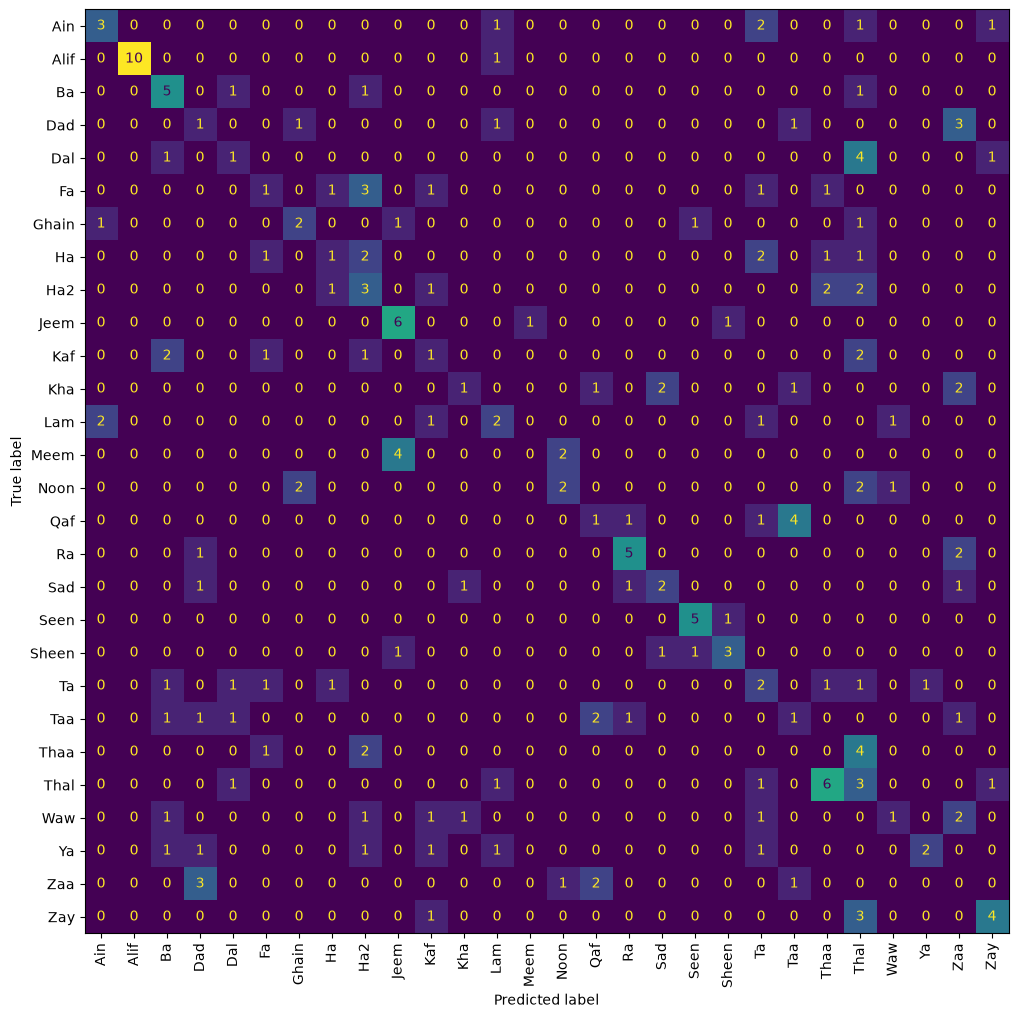

In [8]:
from sklearn.metrics import ConfusionMatrixDisplay

val_out = pd.DataFrame({"label": val_df["label"], "prediction": [id2label[int(i)] for i in pred]})
val_out["correct"] = val_out["label"] == val_out["prediction"]
print(val_out.groupby("label")["correct"].mean().sort_values())          # accuracy per letter

fig, ax = plt.subplots(figsize=(12, 12))
ConfusionMatrixDisplay.from_predictions(val_out["label"], val_out["prediction"], xticks_rotation=90, ax=ax, colorbar=False)
plt.show()

In [9]:
def extract2(path, n_mfcc=20, n_chunks=4, top_db=25):
    audio, sr = load_audio(str(ROOT / path))
    audio, _ = librosa.effects.trim(audio, top_db=top_db)          # cut silence at start and end
    if len(audio) < 2048:                                          # keep very short clips usable
        audio = np.pad(audio, (0, 2048 - len(audio)))
    m = librosa.feature.mfcc(y=audio, sr=sr, n_mfcc=n_mfcc)        # (n_mfcc, frames)
    chunks = np.array_split(m, n_chunks, axis=1)                   # split the word into time parts
    chunk_means = [c.mean(axis=1) for c in chunks]                 # one average per time part (keeps order)
    return np.concatenate(chunk_means + [m.std(axis=1)])           # n_mfcc*n_chunks + n_mfcc features

Xtr2 = np.stack([extract2(p) for p in train_df["file_path"]])
Xva2 = np.stack([extract2(p) for p in val_df["file_path"]])
print(Xtr2.shape)                                                  # expect (1004, 100)

model2 = make_pipeline(StandardScaler(), SVC(C=10)).fit(Xtr2, ytr)
pred2 = model2.predict(Xva2)
print("val accuracy:", round(accuracy_score(yva, pred2), 3))
print("val macro-F1:", round(f1_score(yva, pred2, average="macro"), 3))

(1004, 100)
val accuracy: 0.558
val macro-F1: 0.588


In [10]:
#testing the diff n_mfcc and n_chunks values and their effect on the accuracy and macro-F1 score of the SVM model. The goal is to find the optimal combination of n_mfcc and n_chunks that yields the best performance on the validation set.

from itertools import product #helps to generate all possible combinations of n_mfcc and n_chunks values to test. This allows us to systematically explore the parameter space and identify the best configuration for our model.


def mfcc_matrix(path, n_mfcc, top_db=25):
    """One file -> MFCC matrix (n_mfcc, frames), after trimming silence."""
    audio, sr = load_audio(str(ROOT / path))
    audio, _ = librosa.effects.trim(audio, top_db=top_db)
    if len(audio) < 4096:                                    # keep at least ~9 frames
        audio = np.pad(audio, (0, 4096 - len(audio)))
    return librosa.feature.mfcc(y=audio, sr=sr, n_mfcc=n_mfcc)

def pool(m, n_chunks):
    """MFCC matrix -> fixed-length vector (per-time-chunk means + overall std)."""
    chunks = np.array_split(m, n_chunks, axis=1)
    return np.concatenate([c.mean(axis=1) for c in chunks] + [m.std(axis=1)])

rows = []
for n_mfcc in [13, 20, 40]:
    mats_tr = [mfcc_matrix(p, n_mfcc) for p in train_df["file_path"]]     # extract once per n_mfcc
    mats_va = [mfcc_matrix(p, n_mfcc) for p in val_df["file_path"]]
    for n_chunks, C in product([3, 4, 5], [1, 10, 100]):
        Xtr_g = np.stack([pool(m, n_chunks) for m in mats_tr])
        Xva_g = np.stack([pool(m, n_chunks) for m in mats_va])
        p = make_pipeline(StandardScaler(), SVC(C=C)).fit(Xtr_g, ytr).predict(Xva_g)
        rows.append((n_mfcc, n_chunks, C, accuracy_score(yva, p), f1_score(yva, p, average="macro")))
    print("done n_mfcc =", n_mfcc)

grid = pd.DataFrame(rows, columns=["n_mfcc", "n_chunks", "C", "acc", "macro_f1"])
display(grid.sort_values("macro_f1", ascending=False).head(10))



done n_mfcc = 13
done n_mfcc = 20
done n_mfcc = 40


,n_mfcc,n_chunks,C,acc,macro_f1
8,13,5,100,0.646512,0.677829
7,13,5,10,0.646512,0.677829
4,13,4,10,0.641860,0.672400
5,13,4,100,0.641860,0.672400
1,13,3,10,0.623256,0.650577
2,13,3,100,0.623256,0.650577
14,20,4,100,0.558140,0.587632
13,20,4,10,0.558140,0.587632
17,20,5,100,0.548837,0.576661
16,20,5,10,0.548837,0.576661


In [ ]:
# C controls how strict the SVM is about training errors:
#   - Small C (e.g. 1):   smooth, simple decision boundaries; tolerates some training mistakes.
#                         Risk: underfitting (too simple to separate the letters).
#   - Medium C (e.g. 10): balanced trade-off between fitting the training data and staying simple.
#   - Large C (e.g. 100): strict, complex boundaries; tries to classify every training file correctly.
#                         Risk: overfitting (memorizes the training set, worse on new recordings).
#
# In our results C=10 and C=100 gave identical scores: the SVM already separates all
# training samples at C=10, so a larger C changes nothing.
# Rule used: when scores are equal, pick the simpler (smaller) C, so we use C=10.

### Key Findings

1. **MFCC coefficients:** `n_mfcc=13` performed significantly better than `n_mfcc=20` (accuracy: ~0.65 vs. ~0.55). The first 13 coefficients may capture the most useful overall speech characteristics, while higher coefficients may introduce speaker-specific details.

2. **Temporal chunks:** Increasing `n_chunks` from 3 to 5 improved performance. However, the difference between 4 and 5 chunks was only ~0.5% (about one file), so it may not be statistically significant.

In [11]:
#trying to find out what is the best n and chunks values for the MFCC feature extraction and pooling process. The goal is to identify the combination of n_mfcc and n_chunks that yields the highest accuracy and macro-F1 score on the validation set, which will help in optimizing the SVM model's performance.

rows = []
for n_mfcc in [10, 13]:
    mats_tr = [mfcc_matrix(p, n_mfcc) for p in train_df["file_path"]]
    mats_va = [mfcc_matrix(p, n_mfcc) for p in val_df["file_path"]]
    for n_chunks, C in product([5, 6, 7, 8], [1, 10]):
        Xtr_g = np.stack([pool(m, n_chunks) for m in mats_tr])
        Xva_g = np.stack([pool(m, n_chunks) for m in mats_va])
        assert not np.isnan(Xtr_g).any() and not np.isnan(Xva_g).any()   # an empty chunk would give NaN
        p = make_pipeline(StandardScaler(), SVC(C=C)).fit(Xtr_g, ytr).predict(Xva_g)
        rows.append((n_mfcc, n_chunks, C, accuracy_score(yva, p), f1_score(yva, p, average="macro")))

grid2 = pd.DataFrame(rows, columns=["n_mfcc", "n_chunks", "C", "acc", "macro_f1"])
display(grid2.sort_values("macro_f1", ascending=False).head(8))


,n_mfcc,n_chunks,C,acc,macro_f1
5,10,7,10,0.697674,0.726789
1,10,5,10,0.697674,0.724703
7,10,8,10,0.688372,0.713780
3,10,6,10,0.674419,0.705118
13,13,7,10,0.669767,0.698084
11,13,6,10,0.655814,0.687693
9,13,5,10,0.646512,0.677829
15,13,8,10,0.641860,0.672660


the best : n_mfcc=10 C=10 n_chunks=5

In [12]:
import joblib

BEST = dict(n_mfcc=10, n_chunks=5, C=10)       # final baseline settings

def feats(df):
    # file -> MFCC matrix -> fixed-length vector, using the chosen settings
    return np.stack([pool(mfcc_matrix(p, BEST["n_mfcc"]), BEST["n_chunks"]) for p in df["file_path"]])

Xtr_f, Xva_f = feats(train_df), feats(val_df)
print(Xtr_f.shape)                              # expect (1004, 60)

baseline = make_pipeline(StandardScaler(), SVC(C=BEST["C"])).fit(Xtr_f, ytr)   # fit on TRAIN only
pv = baseline.predict(Xva_f)
print("val acc:", round(accuracy_score(yva, pv), 3), "| val macro-F1:", round(f1_score(yva, pv, average="macro"), 3))

# Save the model, its settings, and its validation predictions (needed later to compare with Wav2Vec2)
Path("../models").mkdir(exist_ok=True)
joblib.dump(baseline, "../models/baseline_svm.joblib")
json.dump(BEST, open("../models/baseline_config.json", "w"))
pd.DataFrame({"path": val_df["file_path"], "label": val_df["label"],
              "prediction": [id2label[int(i)] for i in pv]}).to_csv("../baseline_val_results.csv", index=False)

(1004, 60)
val acc: 0.698 | val macro-F1: 0.725
